In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Google Colab: download the project code (evqaoa/, experiments/, results/) if it is not here yet.
import os, sys
if 'google.colab' in sys.modules and not (os.path.isdir('evqaoa') or os.path.isdir('../evqaoa')):
    !git clone -q https://github.com/SakxamShrestha/quant5-fisk-IQ-hackathon
    %cd quant5-fisk-IQ-hackathon/notebooks

In [2]:
import sys, os
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
OUT = os.path.join(ROOT, 'results', '02_pareto')
os.makedirs(OUT, exist_ok=True)

# 02 - Reconstructing the Pareto front with many weightings

**Where this comes from.** The hackathon's QAOA starter notebook optimises *one* weighted objective, so it returns one compromise schedule. A depot operator would rather see the whole **trade-off menu**: the *Pareto front*, i.e. the schedules where you cannot improve cost, peak load or battery wear without making another one worse.

**Our depot.** 3 vehicles x 4 night slots = 12 qubits. Tariff (32, 14, 9, 21) cents/kWh, demands (2, 1, 2) slots. Only 144 of the 4096 bitstrings are valid schedules (3.5%).

**Workflow**
1. Brute-force the 144 valid schedules and find the true front.
2. Sweep weightings on the simplex (w_cost + w_peak + w_switch = 1, step 1/8, 45 weightings).
3. For each weighting: build the Hamiltonian, run depth p=2 QAOA with the XY mixer and Dicke start (every shot is a valid schedule), tune the angles with COBYLA on the exact statevector, then draw 256 shots.
4. Pool the shots and compare the non-dominated schedules found against the true front. Two angle strategies: **independent** (random start for every weighting) and **warm-started** (start from the previous weighting's angles).
5. Baselines with the same shot budget: a random *valid* schedule, and a random 12-bit string (invalid ones are wasted).

**Metrics.** Front points recovered; hypervolume (volume dominated, measured up to a reference point just worse than every metric's maximum; bigger is better); shots needed to see the whole front.

In [3]:
import json, time
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from evqaoa import DEPOT, schedule_metrics, valid_schedules, non_dominated, charging_model, metric_ranges
from experiments.pareto import (weight_grid, run_weighting, front_recovery, hypervolume, random_baseline,
                                cumulative_curves, shots_to_full_front, COBYLA_TOL, MAXITER)

SHOTS_PER_WEIGHTING, DENOM, P = 256, 8, 2
NAMES = ['energy cost', 'peak load', 'switches']
table = [schedule_metrics(DEPOT, x) for x in valid_schedules(DEPOT)]
true_front = non_dominated(table)
ref = tuple(float(v) + 1 for v in np.max(table, axis=0))
hv_true = hypervolume(true_front, ref)
print('valid schedules:', len(table), '| distinct metric triples:', len(set(table)))
print('true front (', len(true_front), 'points ):')
for q in true_front: print('  ', q)
print('reference point:', ref, '| hypervolume of true front:', hv_true)

valid schedules: 144 | distinct metric triples: 60
true front ( 9 points ):
   (55.0, 13.0, 6.0)
   (62.0, 11.0, 5.0)
   (67.0, 9.0, 5.0)
   (69.0, 13.0, 4.0)
   (74.0, 9.0, 4.0)
   (81.0, 13.0, 3.0)
   (85.0, 7.0, 4.0)
   (92.0, 9.0, 3.0)
   (97.0, 7.0, 3.0)
reference point: (139.0, 14.0, 9.0) | hypervolume of true front: 2721.0


## 1. QAOA sweep over the 45 weightings
Both sweeps use the same optimiser settings: COBYLA, at most 400 evaluations, stopping early when it converges to tolerance 0.003. We record how often it still hits the cap.

In [4]:
grid = weight_grid(DENOM)
t0 = time.time()
cold = [run_weighting(DEPOT, w, p=P, shots=SHOTS_PER_WEIGHTING, seed=i) for i, w in enumerate(grid)]
t_cold = time.time() - t0
t0 = time.time()
warm, prev = [], None
for i, w in enumerate(grid):
    r = run_weighting(DEPOT, w, p=P, start=prev, shots=SHOTS_PER_WEIGHTING, seed=1000 + i)
    prev = r['theta']; warm.append(r)
t_warm = time.time() - t0
for name, runs, t in [('independent', cold, t_cold), ('warm-start', warm, t_warm)]:
    print(f'{name:12s} {t:5.0f}s | mean evaluations {np.mean([r["nfev"] for r in runs]):.0f} '
          f'| hit the cap {sum(r["hit_cap"] for r in runs)}/{len(runs)} | mean energy {np.mean([r["energy"] for r in runs]):.4f}')

independent    313s | mean evaluations 332 | hit the cap 34/45 | mean energy 0.5918
warm-start     317s | mean evaluations 245 | hit the cap 20/45 | mean energy 0.5843


## 2. Sampled schedules vs. the baselines (equal shot budget)
QAOA shots are ordered weighting by weighting, so its curve mixes early and late weightings. Random baselines are averaged over 20 seeds.

In [5]:
def flatten(runs): return [s for r in runs for s in r['samples']]
seq = {'QAOA independent': flatten(cold), 'QAOA warm-start': flatten(warm)}
budget = len(seq['QAOA independent'])
SEEDS = range(20)
rand_valid = [random_baseline(DEPOT, budget, seed=s, valid_only=True) for s in SEEDS]
rand_bits = [random_baseline(DEPOT, budget, seed=s, valid_only=False) for s in SEEDS]
checkpoints = sorted(set(list(range(256, budget + 1, 256)) + [16, 32, 64, 128, budget]))

def mean_curve(runs):
    cs = [cumulative_curves(r, true_front, ref, checkpoints) for r in runs]
    return [np.mean([c[i] for c in cs], axis=0) for i in (0, 1)]

curves = {k: cumulative_curves(v, true_front, ref, checkpoints) for k, v in seq.items()}
curves['Random valid schedule (mean of 20)'] = tuple(mean_curve(rand_valid))
curves['Random 12-bit string (mean of 20)'] = tuple(mean_curve(rand_bits))
valid_share = {k: float(np.mean([s is not None for s in v])) for k, v in seq.items()}
valid_share['random 12-bit'] = float(np.mean([s is not None for r in rand_bits for s in r]))
summary = {k: dict(front_found=float(v[0][-1]), hypervolume=float(v[1][-1]), hv_fraction=float(v[1][-1] / hv_true))
           for k, v in curves.items()}
for k, v in summary.items():
    print(f'{k:36s} front {v["front_found"]:.2f}/{len(true_front)}  HV {v["hypervolume"]:.1f} ({100*v["hv_fraction"]:.1f}% of true)')
print('share of valid shots:', {k: round(v, 3) for k, v in valid_share.items()})

full = dict(qaoa_independent=shots_to_full_front(seq['QAOA independent'], true_front),
            qaoa_warm=shots_to_full_front(seq['QAOA warm-start'], true_front),
            random_valid=[shots_to_full_front(r, true_front) for r in rand_valid],
            random_bits=[shots_to_full_front(r, true_front) for r in rand_bits])
def stat(xs):
    ok = [x for x in xs if x is not None]
    return f'{len(ok)}/{len(xs)} seeds complete, median {int(np.median(ok)) if ok else None}, range {min(ok) if ok else None}-{max(ok) if ok else None}'
print('shots to see all', len(true_front), 'front points:')
print('  QAOA independent', full['qaoa_independent'], '| QAOA warm-start', full['qaoa_warm'])
print('  random valid:', stat(full['random_valid']))
print('  random 12-bit:', stat(full['random_bits']))
at256 = {k: float(v[0][checkpoints.index(256)]) for k, v in curves.items()}
print('front points after the first 256 shots:', {k: round(v, 2) for k, v in at256.items()})

QAOA independent                     front 9.00/9  HV 2721.0 (100.0% of true)
QAOA warm-start                      front 9.00/9  HV 2721.0 (100.0% of true)
Random valid schedule (mean of 20)   front 9.00/9  HV 2721.0 (100.0% of true)
Random 12-bit string (mean of 20)    front 8.85/9  HV 2717.0 (99.9% of true)
share of valid shots: {'QAOA independent': 1.0, 'QAOA warm-start': 1.0, 'random 12-bit': 0.036}
shots to see all 9 front points:
  QAOA independent 770 | QAOA warm-start 723
  random valid: 20/20 seeds complete, median 262, range 111-552
  random 12-bit: 17/20 seeds complete, median 6573, range 3136-10690
front points after the first 256 shots: {'QAOA independent': 8.0, 'QAOA warm-start': 8.0, 'Random valid schedule (mean of 20)': 8.35, 'Random 12-bit string (mean of 20)': 0.9}


## 3. Plot: the objective space
Grey: all valid schedules. Red stars: the true front. Blue dots: schedules QAOA sampled. Blue rings: front points QAOA found.

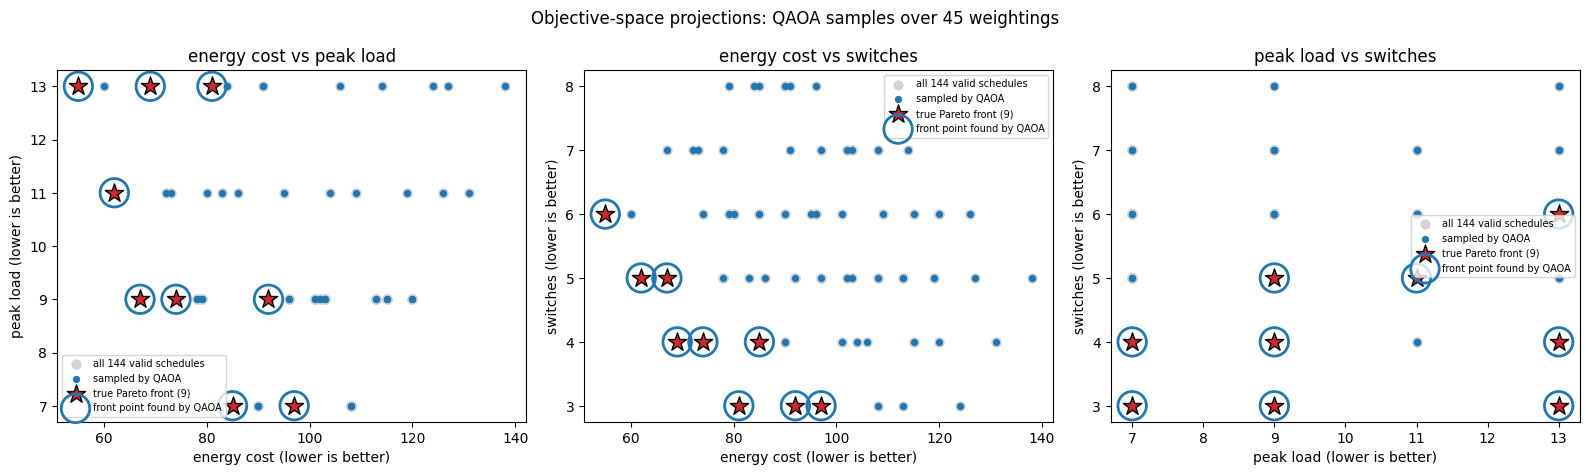

In [6]:
qaoa_pts = sorted({s for k in seq for s in seq[k] if s})
front_set = set(true_front)
qaoa_front = [q for q in qaoa_pts if q in front_set]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    ax.scatter([t[a] for t in table], [t[b] for t in table], c='lightgrey', s=40, label='all 144 valid schedules')
    ax.scatter([t[a] for t in qaoa_pts], [t[b] for t in qaoa_pts], c='tab:blue', s=18, label='sampled by QAOA')
    ax.scatter([t[a] for t in true_front], [t[b] for t in true_front], c='tab:red', marker='*', s=190,
               edgecolors='k', label='true Pareto front (%d)' % len(true_front))
    ax.scatter([t[a] for t in qaoa_front], [t[b] for t in qaoa_front], facecolors='none', edgecolors='tab:blue',
               s=420, linewidths=2, label='front point found by QAOA')
    ax.set_xlabel(NAMES[a] + ' (lower is better)'); ax.set_ylabel(NAMES[b] + ' (lower is better)')
    ax.set_title(f'{NAMES[a]} vs {NAMES[b]}'); ax.legend(fontsize=7)
fig.suptitle('Objective-space projections: QAOA samples over 45 weightings')
fig.tight_layout(); fig.savefig(f'{OUT}/projections.png', dpi=140); plt.show()

## 4. Plots: front points recovered and hypervolume vs. shots

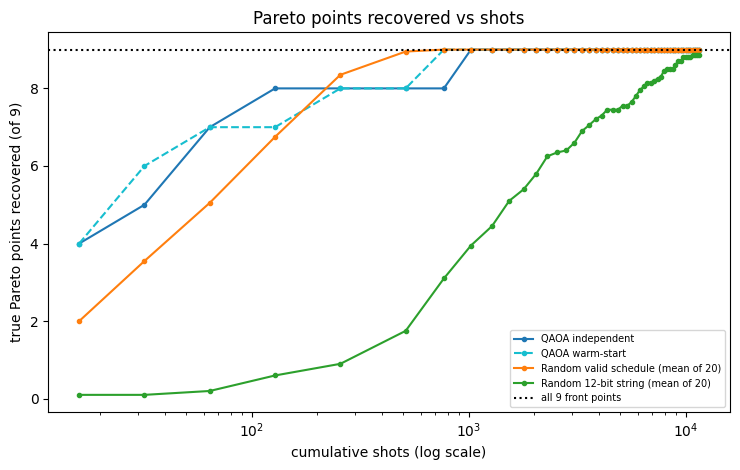

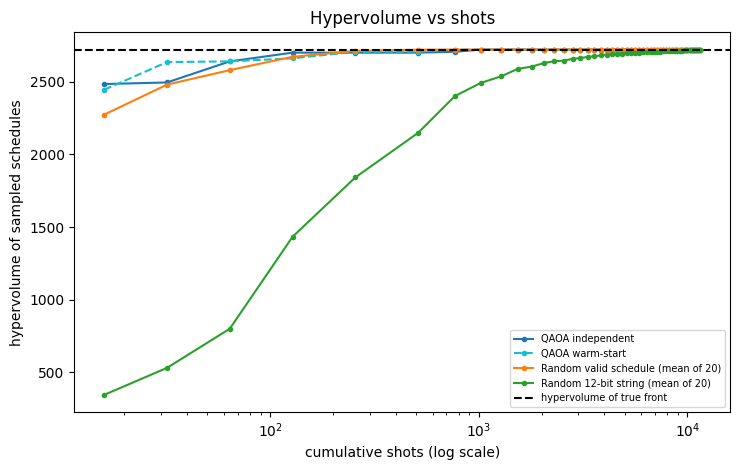

In [7]:
STYLE = {'QAOA independent': ('tab:blue', '-'), 'QAOA warm-start': ('tab:cyan', '--'),
         'Random valid schedule (mean of 20)': ('tab:orange', '-'),
         'Random 12-bit string (mean of 20)': ('tab:green', '-')}
nf = len(true_front)
for idx, (ylabel, title, fname) in enumerate([
        (f'true Pareto points recovered (of {nf})', 'Pareto points recovered vs shots', 'recovery_vs_shots.png'),
        ('hypervolume of sampled schedules', 'Hypervolume vs shots', 'hypervolume_vs_shots.png')]):
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    for k, (col, ls) in STYLE.items():
        ax.plot(checkpoints, curves[k][idx], color=col, ls=ls, marker='o', ms=3, label=k)
    if idx == 0: ax.axhline(nf, color='k', ls=':', label=f'all {nf} front points')
    else: ax.axhline(hv_true, color='k', ls='--', label='hypervolume of true front')
    ax.set_xscale('log'); ax.set_xlabel('cumulative shots (log scale)'); ax.set_ylabel(ylabel)
    ax.set_title(title); ax.legend(fontsize=7); fig.tight_layout()
    fig.savefig(f'{OUT}/{fname}', dpi=140); plt.show()

## 5. Which weighting hits which front point?
Per front point: how many of the 45 weightings (independent sweep) produced it at least once, and the weighting that produced it most often. The map shows the most-sampled schedule of each weighting.

(55.0, 13.0, 6.0) hit by 30/45 weightings | top weighting (cost,peak,switch) = (1.0, 0.0, 0.0) | hits 47
(62.0, 11.0, 5.0) hit by 43/45 weightings | top weighting (cost,peak,switch) = (0.75, 0.125, 0.125) | hits 25
(67.0, 9.0, 5.0) hit by 44/45 weightings | top weighting (cost,peak,switch) = (0.875, 0.0, 0.125) | hits 49
(69.0, 13.0, 4.0) hit by 32/45 weightings | top weighting (cost,peak,switch) = (0.375, 0.5, 0.125) | hits 14
(74.0, 9.0, 4.0) hit by 44/45 weightings | top weighting (cost,peak,switch) = (0.125, 0.0, 0.875) | hits 25
(81.0, 13.0, 3.0) hit by 32/45 weightings | top weighting (cost,peak,switch) = (0.0, 0.0, 1.0) | hits 22
(85.0, 7.0, 4.0) hit by 43/45 weightings | top weighting (cost,peak,switch) = (0.625, 0.0, 0.375) | hits 39
(92.0, 9.0, 3.0) hit by 33/45 weightings | top weighting (cost,peak,switch) = (0.0, 0.125, 0.875) | hits 19
(97.0, 7.0, 3.0) hit by 39/45 weightings | top weighting (cost,peak,switch) = (0.0, 0.0, 1.0) | hits 30


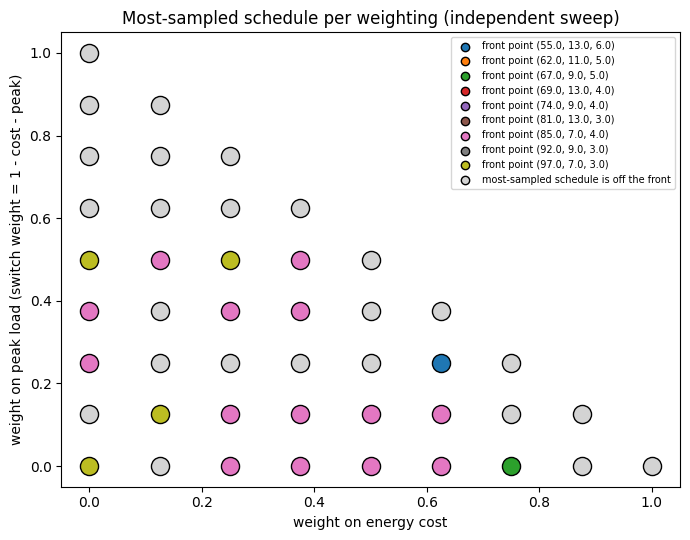

distinct front points that are the most-sampled schedule of some weighting: 4


In [8]:
found_by = {q: [] for q in true_front}
for r in cold:
    for q in true_front:
        n = sum(1 for s in r['samples'] if s == q)
        if n: found_by[q].append((r['weights'], n))
for q, lst in found_by.items():
    best = max(lst, key=lambda t: t[1]) if lst else None
    print(q, f'hit by {len(lst):2d}/{len(grid)} weightings | top weighting (cost,peak,switch) =',
          best[0] if best else None, '| hits', best[1] if best else 0)

modes = [Counter(s for s in r['samples'] if s).most_common(1)[0][0] for r in cold]
colour_of = {q: plt.cm.tab10(i) for i, q in enumerate(true_front)}
fig, ax = plt.subplots(figsize=(7, 5.5))
for w, m in zip(grid, modes):
    ax.scatter(w[0], w[1], s=170, c=[colour_of[m]] if m in colour_of else 'lightgrey', edgecolors='k')
for q in true_front: ax.scatter([], [], c=[colour_of[q]], edgecolors='k', label=f'front point {q}')
ax.scatter([], [], c='lightgrey', edgecolors='k', label='most-sampled schedule is off the front')
ax.set_xlabel('weight on energy cost'); ax.set_ylabel('weight on peak load (switch weight = 1 - cost - peak)')
ax.set_title('Most-sampled schedule per weighting (independent sweep)'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{OUT}/weighting_map.png', dpi=140); plt.show()
n_modes_on_front = len(set(m for m in modes if m in front_set))
print('distinct front points that are the most-sampled schedule of some weighting:', n_modes_on_front)

## 6. Can weighted sums reach every front point at all?
Exact check, no quantum: for each of the 45 weightings, find the best valid schedule of the weighted objective. Front points that are never the optimum of any weighting (the "unsupported" ones) can only appear in QAOA's samples by chance.

In [9]:
scores = []
for w in grid:
    vals = charging_model(DEPOT, w).values(np.array(list(valid_schedules(DEPOT))))
    best = vals.min()
    scores.append({table[i] for i in np.flatnonzero(np.isclose(vals, best, atol=1e-9))})
exact_hits = set().union(*scores)
supported = [q for q in true_front if q in exact_hits]
print('front points that are an exact optimum (incl. ties) of some weighting:', len(supported), 'of', len(true_front))
print('never an optimum of any grid weighting:', [q for q in true_front if q not in exact_hits])

result = dict(grid=grid, shots_per_weighting=SHOTS_PER_WEIGHTING, p=P, cobyla_tol=COBYLA_TOL, cobyla_maxiter=MAXITER,
              true_front=true_front, reference_point=ref, hv_true=hv_true, checkpoints=checkpoints, summary=summary,
              valid_share=valid_share, front_after_256_shots=at256, shots_to_full_front=full,
              runtime_s=dict(independent=t_cold, warm_start=t_warm),
              exact_scalarisation_front_points=len(supported),
              optimiser=dict((n, dict(mean_nfev=float(np.mean([r['nfev'] for r in rs])),
                                      hit_cap=int(sum(r['hit_cap'] for r in rs)),
                                      mean_energy=float(np.mean([r['energy'] for r in rs]))))
                             for n, rs in [('independent', cold), ('warm_start', warm)]),
              curves={k: dict(recovered=[float(x) for x in v[0]], hypervolume=[float(x) for x in v[1]]) for k, v in curves.items()},
              found_by={str(q): [dict(weights=l, hits=n) for l, n in lst] for q, lst in found_by.items()},
              angles_independent=[dict(weights=r['weights'], theta=r['theta'], energy=r['energy']) for r in cold])
with open(f'{OUT}/pareto_results.json', 'w') as f:
    json.dump(result, f, indent=1, default=float)

front points that are an exact optimum (incl. ties) of some weighting: 9 of 9
never an optimum of any grid weighting: []


## Findings & limitations

**What the sweep achieves.** One weighting returns one schedule; 45 weightings (256 shots each, 11,520 shots in total, p=2, XY mixer + Dicke start) recovered **all 9 of 9** true Pareto points with both angle strategies, so the sampled schedules reach the full hypervolume (2721 of 2721, reference point (139, 14, 9)). Every shot was a valid schedule (100%), because the XY mixer and Dicke start keep each vehicle's charging count fixed. Individual weightings already cover many front points: each point was sampled by 30 to 44 of the 45 weightings, since QAOA's output distribution is broad rather than a single peak. The most-sampled schedule of a weighting was a front point for only 4 distinct front points, so the sweep leans on this breadth, not on sharp optima. Extreme weightings find the extreme points most often (cost only: (55, 13, 6); switches only: (97, 7, 3) and (81, 13, 3)). The exact weighted optima of the grid already cover all 9 front points, so a weighted sum is enough on this instance; there are no "unsupported" points.

**Honest comparison with random sampling.** Uniform random sampling over valid schedules does as well as QAOA, and faster. It also reaches 9/9 and full hypervolume at the same budget (mean of 20 seeds), needs a median of 262 shots to see the whole front (range 111-552, 20 of 20 seeds), whereas QAOA needed 770 shots (independent) and 723 (warm-started). After the first 256 shots QAOA had 8 front points against 8.35 on average for random valid. QAOA beats a random 12-bit string clearly (8.85/9 at 11,520 shots; only 3.6% of those shots are valid; median 6,573 shots to see the full front, and 3 of 20 seeds never did), but that baseline is weak because our circuit already enforces the constraints. The fair comparison is random valid, and QAOA does not win it. With only 144 valid schedules and 9 front points, the problem is simply too small for sampling to be hard. A quirk of the ordering is that QAOA shots arrive weighting by weighting, and neighbouring weightings resample similar schedules.

**Warm start.** Starting each weighting from the previous angles used fewer optimiser evaluations (mean 245 vs 332 per weighting), reached slightly lower mean energy (0.584 vs 0.592) and needed a few fewer shots to see the full front (723 vs 770). The shot difference is one run with one seed, so we do not claim it is significant. The sweep took about 313 s (independent) and 317 s (warm) of wall-clock time on a shared CPU; the evaluation saving did not show up as time saved here.

**Limitations.** (1) COBYLA, capped at 400 evaluations with tolerance 3e-3, still hit the cap in 34 of 45 independent runs and 20 of 45 warm-started ones, so many angle sets are not fully converged. (2) Exact statevector probabilities, no hardware noise; shot noise comes only from the 256 draws. (3) One instance, one seed per QAOA sweep, p=2 only. (4) The 45-point grid and equal-weight normalisation by each metric's maximum are our choices; other scalarisations could change which points are easy. (5) Real value of QAOA here would only show on larger depots, where valid schedules are too many to enumerate or sample uniformly; this study does not test that.